## MTL Trajet: 13 Single-day Locational Patterns (Flag 13)

### Dataset Overview
One day's urban trajectories with temporal period, origin and destination zones, destination land use, distance, mode, and timestamped GPS points. GPS coordinates preserve the selected observed MTL route geometry.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Find obvious locational features of given trajectories within one day.

Role: Urban trajectory-pattern analyst


Category: Single-day rush-hour direction, trip distance, mode, city-zone, and agricultural destination patterns

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do the predominant origin-to-destination directions differ between morning and evening rush hours?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

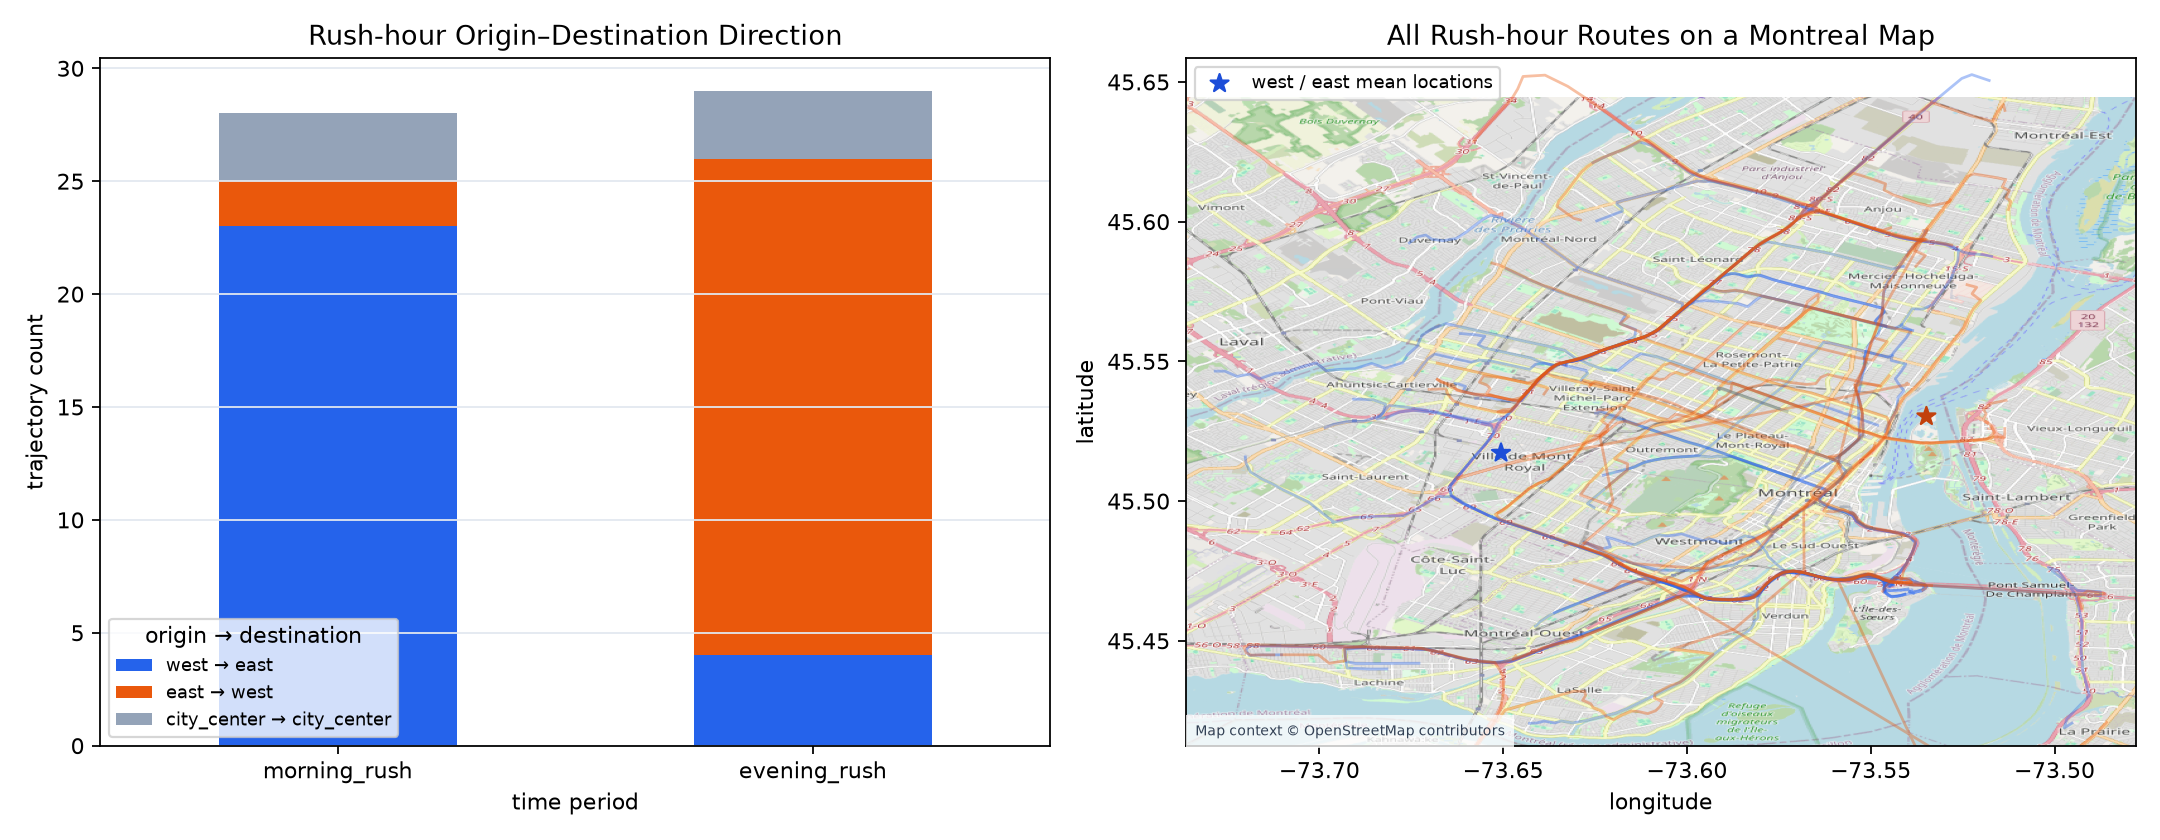

In [ ]:
pd.crosstab(df.time_period, df.origin_zone + ' → ' + df.destination_zone)
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/rush_hour_directional_flows.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "rush_hour_directional_flow",
  "insight": "During the morning rush, most trajectories travel from the west part of the city to the east part; during the evening rush, most travel from east to west.",
  "insight_type": "overall_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Rush-hour Directional Flows",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/rush_hour_directional_flows.png"
  },
  "question": "How do the predominant origin-to-destination directions differ between morning and evening rush hours?",
  "code": "pd.crosstab(df.time_period, df.origin_zone + ' → ' + df.destination_zone)",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position"
  ]
}

### **Question 2**: When do the very long trips occur, and where do they start and end?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

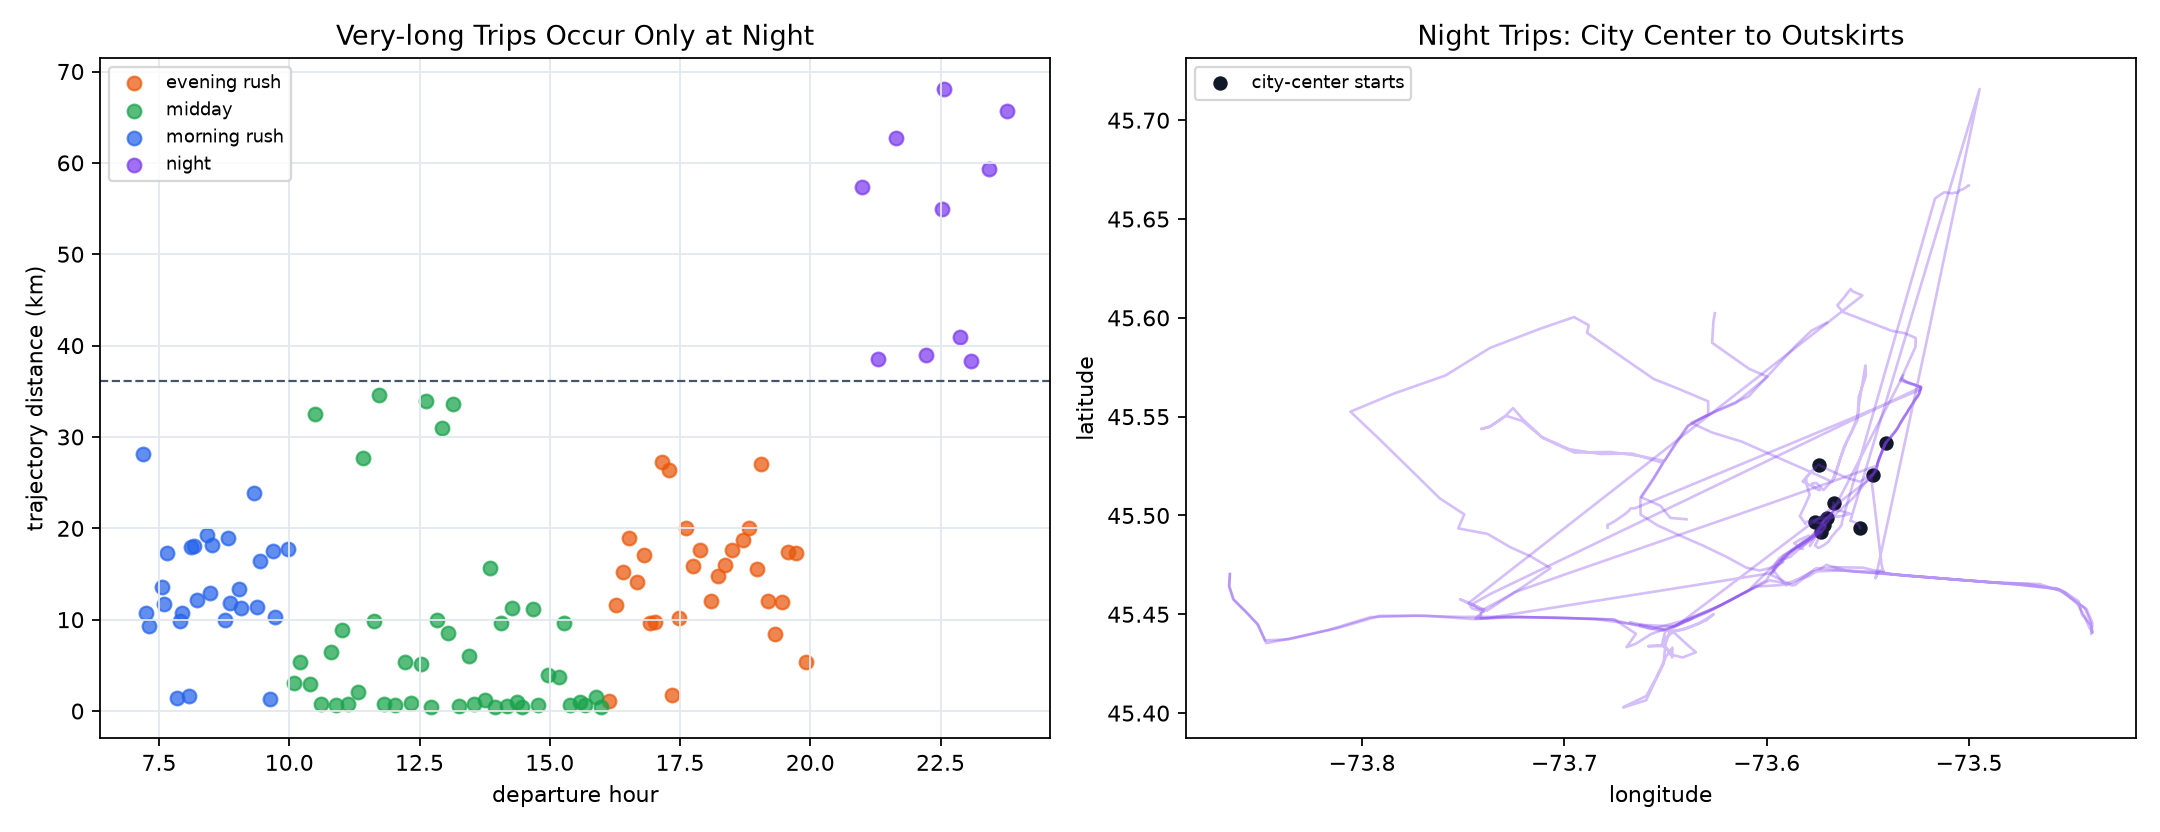

In [ ]:
df[df.is_very_long].groupby(['time_period','origin_zone','destination_zone']).distance_km.agg(['count','min','max'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/night_center_outskirts_long_trips.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "night_long_trip_location",
  "insight": "Very long trips occur only at night and run from the city center to the outskirts.",
  "insight_type": "exception_deviation",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Night Center-to-outskirts Long Trips",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/night_center_outskirts_long_trips.png"
  },
  "question": "When do the very long trips occur, and where do they start and end?",
  "code": "df[df.is_very_long].groupby(['time_period','origin_zone','destination_zone']).distance_km.agg(['count','min','max'])",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "gps_position"
  ]
}

### **Question 3**: Which transportation mode and spatial extent characterize the very short trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

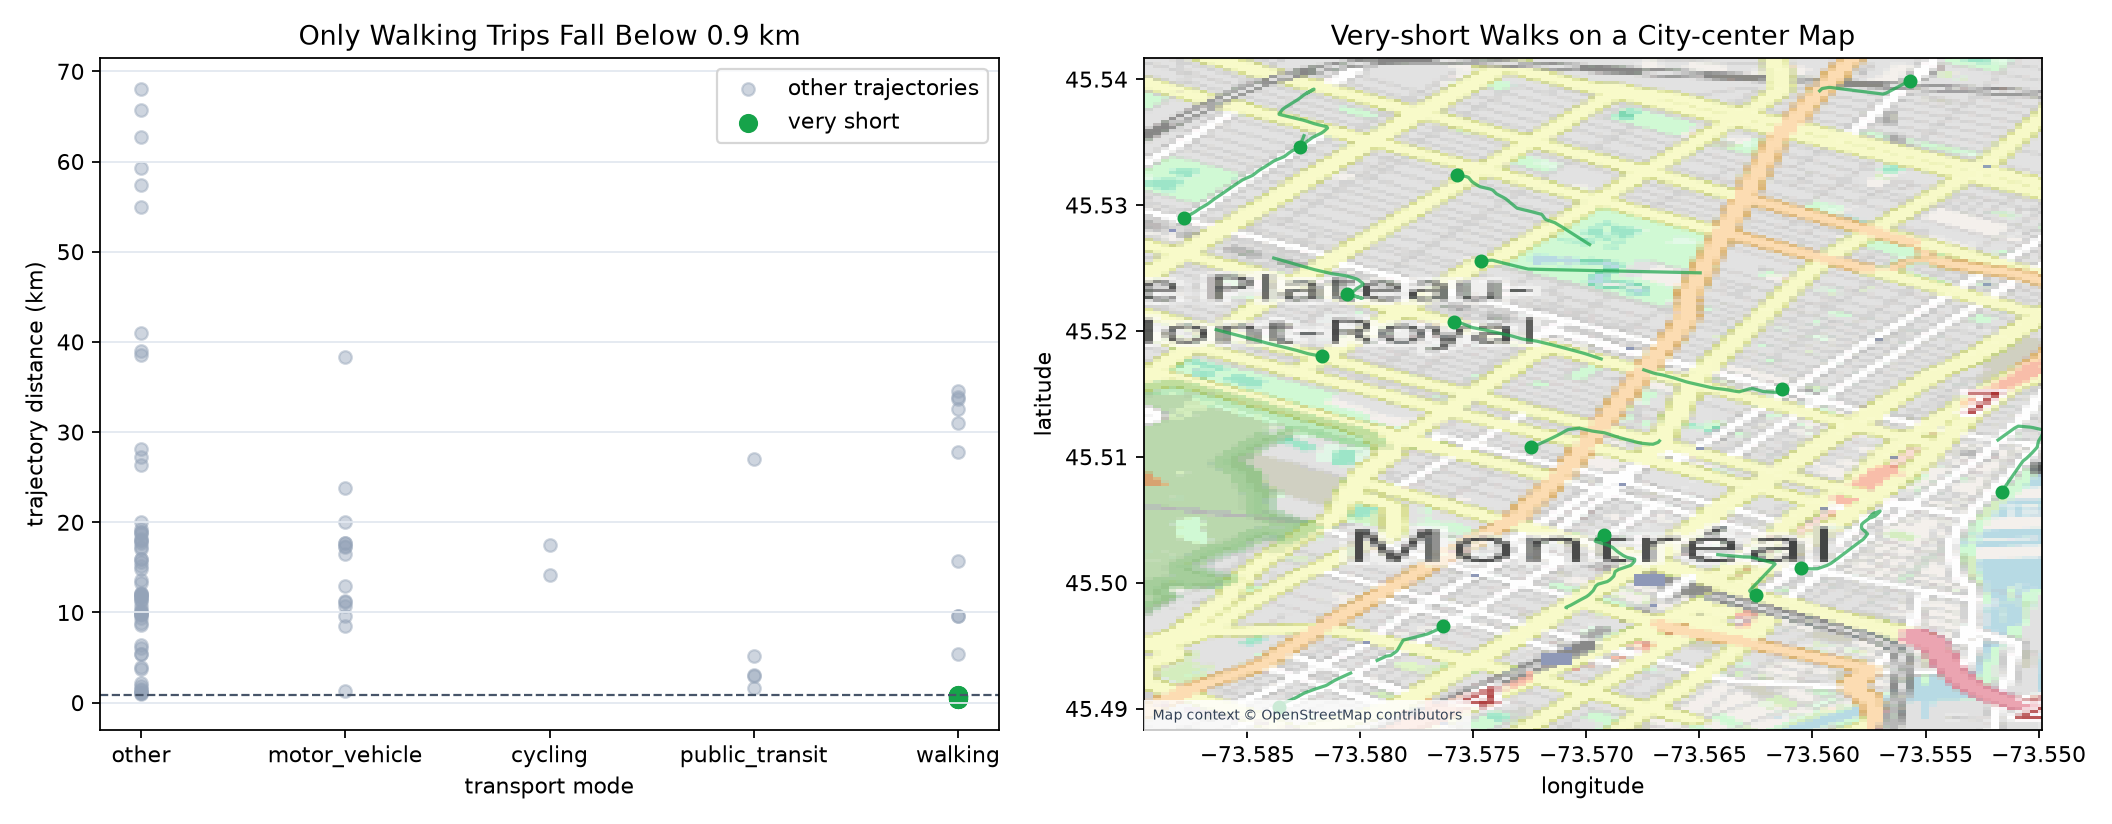

In [ ]:
df[df.is_very_short].groupby(['mode_group','origin_zone','destination_zone']).size()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/short_walking_city_center.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "short_walking_center_pattern",
  "insight": "Very short trips occur only within the city center and use walking.",
  "insight_type": "overall_pattern",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Very-short Walking Trips in the City Center",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/short_walking_city_center.png"
  },
  "question": "Which transportation mode and spatial extent characterize the very short trips?",
  "code": "df[df.is_very_short].groupby(['mode_group','origin_zone','destination_zone']).size()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "transport_mode",
    "trajectory_id"
  ]
}

### **Question 4**: Where in the city do agricultural-related trips end?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

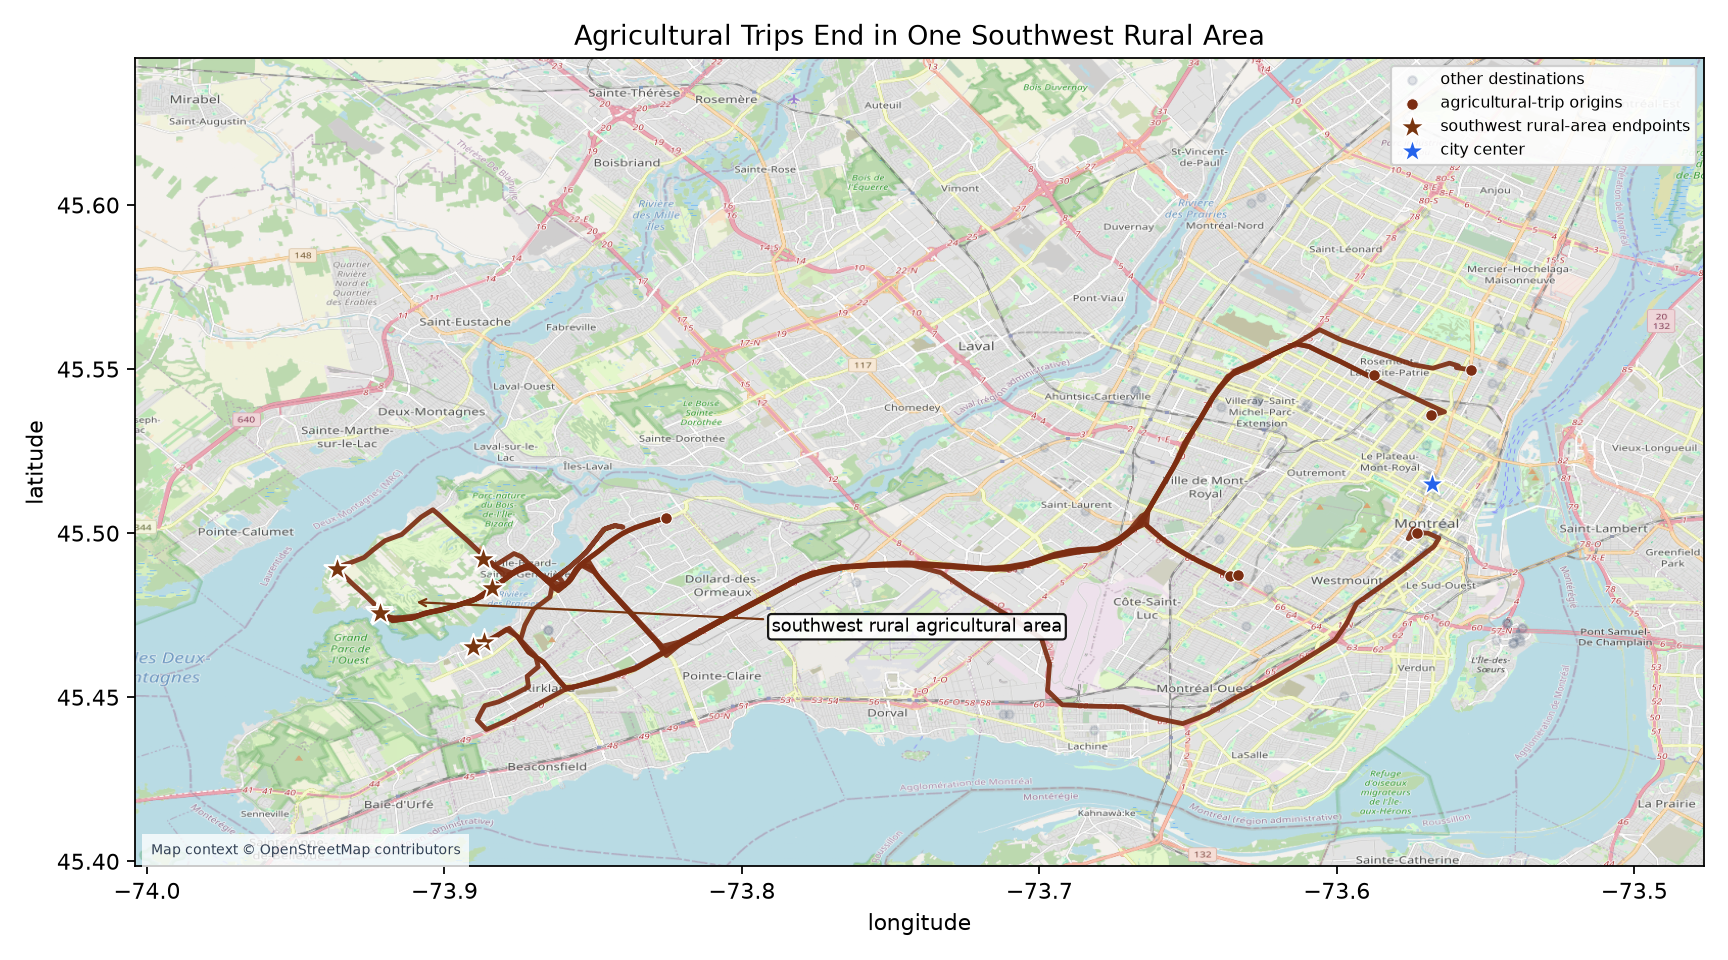

In [ ]:
df[df.destination_land_use.eq('Agricole')][['destination_zone','end_lon','end_lat']].drop_duplicates()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/agricultural_southwest_destination.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "agricultural_rural_destination",
  "insight": "Agricultural-related trips all end in one rural area in the southwest of the city.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Agricultural Southwest Destination",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/agricultural_southwest_destination.png"
  },
  "question": "Where in the city do agricultural-related trips end?",
  "code": "df[df.destination_land_use.eq('Agricole')][['destination_zone','end_lon','end_lat']].drop_duplicates()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "destination_land_use",
    "gps_position",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 13)

This one-day trajectory set has opposing west–east and east–west rush-hour flows, night-only city-center-to-outskirts very-long trips, city-center walking-only short trips, and agricultural trips ending in one southwest rural area.